# Main Pipeline & Model

## Installs & Imports

In [26]:
%%capture
!pip install pandas
!pip install scikit-learn
!pip install numpy
!pip install joblib 
!pip install matplotlib

In [27]:
# Others
import joblib # For model saving and loading
import random # For random state
from enum import Enum

# Important
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ML
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import root_mean_squared_log_error

# Models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

## Config & Helper

In [29]:
# Settings
pd.set_option('display.max_columns', None)

# Config
RANDOM_STATE = 42
def NRANDOM_STATE(i):
    return [0, 1, 67, 69, random.randint(0, 100**100)][i]

METRIC = "neg_root_mean_squared_log_error"

class column(Enum):
    pid = "project_id"
    target = "hours_spent"
    labels = [target, "log_hours", "hours_bucket"]

In [30]:
def column_summary(df: pd.DataFrame) -> pd.DataFrame:
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} cols | "
          f"Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    desc = df.describe(include="all").T
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "nulls": df.isna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2),
        "nunique": df.nunique(dropna=True),
    })
    desc_cols = [
        c for c in ["mean", "std", "min", "25%", "50%", "75%", "max", "top", "freq"]
        if c in desc.columns
    ]
    summary = summary.join(desc[desc_cols])
    summary["skew"] = df.select_dtypes(include="number").skew().round(2)
    summary["sample_vals"] = [df[c].dropna().unique()[:10].tolist() for c in df.columns]
    return summary

## Data & Processing

In [31]:
# Load Data
train_df = pd.read_csv("./train.csv")

# "Status" - First 5 Columns
col_df = column_summary(train_df)

display(train_df.head(3), col_df.head(5))

Shape: 4,500 rows x 73 cols | Memory: 4.54 MB


,project_id,num_commits,active_commit_days,project_span_days,commit_cadence,pct_commits_weekend,pct_commits_late_night,lines_added_total,lines_deleted_total,churn_ratio,median_lines_per_commit,max_lines_in_one_commit,pct_code_in_first_commit,num_commit_authors,avg_commit_msg_length,pct_generic_commit_msgs,num_branches,num_merge_commits,lines_of_code,num_source_files,num_directories,max_dir_depth,num_languages,primary_language,pct_primary_language,num_dependencies,framework,uses_game_engine,has_tests,num_test_files,has_ci_config,has_dockerfile,has_backend,has_database,avg_file_length,comment_line_ratio,num_image_files,num_audio_files,num_3d_model_files,num_font_files,asset_size_mb,has_custom_art,readme_word_count,readme_num_headings,readme_num_images,readme_num_code_blocks,readme_has_install_instructions,has_license,has_docs_folder,url_is_live,hosting_type,page_weight_kb,num_js_files_loaded,num_internal_pages,is_mobile_responsive,has_custom_domain,load_time_ms,description_word_count,project_category,is_multiplayer,mentions_ai_api,is_clone_or_tutorial,stars,forks,num_issues,num_pull_requests,num_releases,is_forked_from_template,author_prior_projects,author_account_age_years,hours_spent,log_hours,hours_bucket
0,535ce026f7,44,15,56,daily,0.2045,0.4545,8500,2900,0.3438,128.5,1600,0.0312,1,38.7273,0.0227,1,0,4600,43,23,5,5,TypeScript,0.9506,20,nextjs,False,False,0,False,True,True,True,107.2791,0.0199,8,0,0,0,0.1,False,401,17,0,5,True,True,False,False,hack-club,NaN,NaN,NaN,NaN,False,NaN,46,app,False,False,False,2,0,0,0,0,False,0,1-2,32.2,3.4726,30-100
1,869ba41ed7,9,3,76,sporadic,0.8889,0.0000,500,100,0.2484,32.0,400,0.0685,2,17.5556,0.7778,1,0,300,2,0,0,1,Python,1.0000,0,none,False,False,0,False,False,False,False,152.0000,0.1053,0,3,0,0,3.0,False,65,1,0,0,True,False,False,True,itch,680.0,3.0,2.0,True,False,800.0,9,game,False,False,False,1,0,0,0,0,False,0,3-5,5.0,1.6094,<10
2,d6f81f8862,12,1,0,frequent,1.0000,0.0000,5900,100,0.0247,64.5,3100,0.1187,3,24.0000,0.3333,1,0,1300,5,0,0,3,JavaScript,0.8421,0,godot,True,False,0,False,False,False,False,269.8000,0.3380,13,0,0,0,2.5,True,16,1,0,0,False,False,False,True,itch,680.0,3.0,3.0,True,False,300.0,11,game,False,False,False,0,0,0,0,0,False,0,3-5,1.3,0.2624,<10


,dtype,non_null,nulls,null_pct,nunique,mean,std,min,25%,50%,75%,max,top,freq,skew,sample_vals
project_id,str,4500,0,0.0,4500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,535ce026f7,1,NaN,"[535ce026f7, 869ba41ed7, d6f81f8862, 152b5d915..."
num_commits,int64,4500,0,0.0,323,55.609111,242.918249,1.0,5.0,13.0,36.0,7720.0,NaN,NaN,17.90,"[44, 9, 12, 4, 7, 2, 78, 18, 27, 21]"
active_commit_days,int64,4500,0,0.0,139,11.679556,42.590948,1.0,2.0,4.0,8.0,1779.0,NaN,NaN,20.73,"[15, 3, 1, 7, 11, 8, 6, 20, 2, 309]"
project_span_days,int64,4500,0,0.0,552,87.483778,271.769422,0.0,0.0,8.0,50.0,6861.0,NaN,NaN,10.56,"[56, 76, 0, 64, 1, 10, 623, 42, 18, 59]"
commit_cadence,str,4500,0,0.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,frequent,2561,NaN,"[daily, sporadic, frequent]"


In [32]:
display(col_df[col_df["dtype"] == "object"], col_df[col_df["dtype"] == "str"])

,dtype,non_null,nulls,null_pct,nunique,mean,std,min,25%,50%,75%,max,top,freq,skew,sample_vals
has_custom_art,object,4498,2,0.04,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,2356,NaN,"[False, True]"
is_mobile_responsive,object,3077,1423,31.62,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,2729,NaN,"[True, False]"
is_multiplayer,object,4495,5,0.11,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,4253,NaN,"[False, True]"
mentions_ai_api,object,4497,3,0.07,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,4211,NaN,"[False, True]"
is_clone_or_tutorial,object,4495,5,0.11,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,3854,NaN,"[False, True]"


,dtype,non_null,nulls,null_pct,nunique,mean,std,min,25%,50%,75%,max,top,freq,skew,sample_vals
project_id,str,4500,0,0.00,4500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,535ce026f7,1,NaN,"[535ce026f7, 869ba41ed7, d6f81f8862, 152b5d915..."
commit_cadence,str,4500,0,0.00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,frequent,2561,NaN,"[daily, sporadic, frequent]"
primary_language,str,4500,0,0.00,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,JavaScript,940,NaN,"[TypeScript, Python, JavaScript, GDScript, non..."
framework,str,4500,0,0.00,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,none,2472,NaN,"[nextjs, none, godot, unity, slack-bot, discor..."
hosting_type,str,4500,0,0.00,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,itch,1088,NaN,"[hack-club, itch, github-pages, custom, vercel..."
project_category,str,4495,5,0.11,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,game,1687,NaN,"[app, game, bot, tool, website, other]"
author_prior_projects,str,4500,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1959,NaN,"[0, 1-2, 6+, 3-5]"
author_account_age_years,str,4500,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1-2,1501,NaN,"[1-2, 3-5, <1, 6+]"
hours_bucket,str,4500,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<10,2985,NaN,"[30-100, <10, 10-30, 100+]"


**So:**
- No duplicate projects
- All "object" columns are booleans
- 3 of the "str" columns are number ranges (will parse them to "int" columns)

### EDA

Raw skew: 3.969 | log1p skew: 0.565
Quantiles: {0.0: 0.1, 0.01: 0.5, 0.05: 1.0, 0.25: 2.7, 0.5: 6.0, 0.75: 12.9, 0.95: 44.01, 0.99: 109.0, 1.0: 140.7}
Exact integer %: 37.02%
Top 10 exact values: {1.0: 219, 2.0: 210, 3.0: 153, 4.0: 131, 5.0: 127, 6.0: 101, 8.0: 94, 1.5: 85, 6.7: 83, 10.0: 70}
              count    min    max
hours_bucket                     
10-30          1120   10.0   30.0
100+             63  100.0  140.7
30-100          332   30.0   98.9
<10            2985    0.1   10.0


Text(0.5, 1.0, 'np.log1p(hours_spent)')

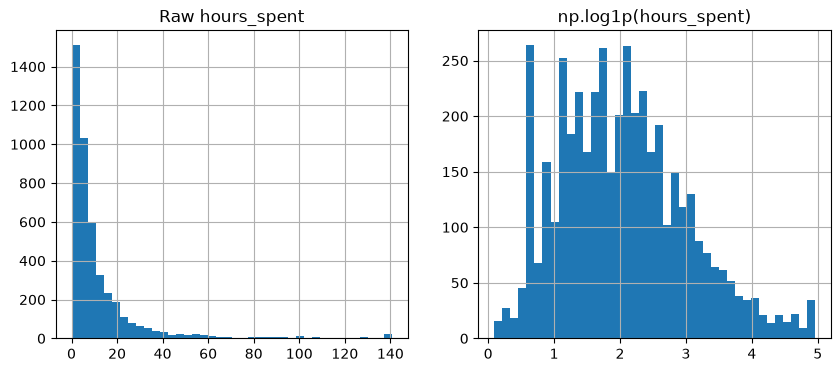

: 

In [ ]:
y = train_df["hours_spent"]
y_log1p = np.log1p(y)

print(f"Raw skew: {y.skew():.3f} | log1p skew: {y_log1p.skew():.3f}")
print("Quantiles:", y.quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]).round(2).to_dict())
print(f"Exact integer %: {(y % 1 == 0).mean() * 100:.2f}%")
print("Top 10 exact values:", y.value_counts().head(10).to_dict())

# Verify bucket boundaries IF auxiliary buckets exist
print(train_df.groupby("hours_bucket")["hours_spent"].agg(["count", "min", "max"]))

# Plots:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y.hist(bins=40, ax=axes[0]); axes[0].set_title("Raw hours_spent")
y_log1p.hist(bins=40, ax=axes[1]); axes[1].set_title("np.log1p(hours_spent)")

### Pre-Processing

## Modelling

## Final